Practica 5 modelo lineal

Se busca estimar el volumen de trafico con datos del clima

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

path = "../data/procesed/metro.csv"
metro = pd.read_csv(path)
metro.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


Datos para el modelo

Se usan las variables numericas del clima para predecir traffic volume

In [2]:
columnas = ["temp", "rain_1h", "snow_1h", "clouds_all"]
x = metro[columnas]
y = metro["traffic_volume"]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

x_train.shape, x_test.shape

((32460, 4), (8115, 4))

Modelo lineal

Se ajusta el modelo con los datos de entrenamiento

In [3]:
modelo = LinearRegression()
modelo.fit(x_train, y_train)

y_pred = modelo.predict(x_test)
r2 = r2_score(y_test, y_pred)

print("r2 del modelo", round(r2, 3))

r2 del modelo 0.028


Volumen real y volumen estimado

La linea muestra donde quedarian las predicciones perfectas

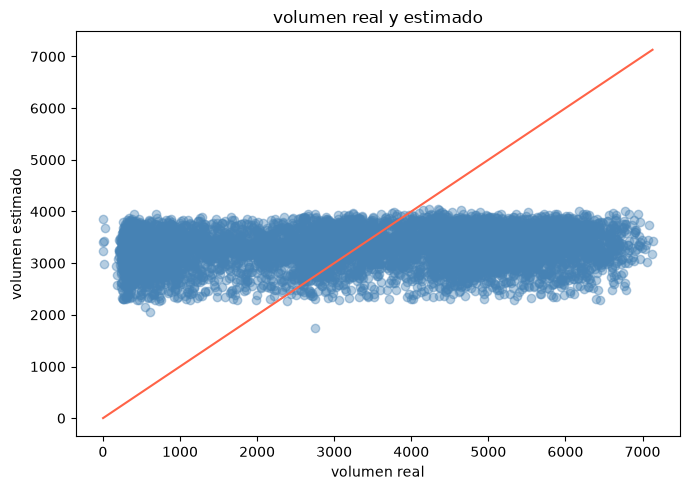

In [4]:
minimo = min(y_test.min(), y_pred.min())
maximo = max(y_test.max(), y_pred.max())

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.4, color="steelblue")
plt.plot([minimo, maximo], [minimo, maximo], color="tomato")
plt.xlabel("volumen real")
plt.ylabel("volumen estimado")
plt.title("volumen real y estimado")
plt.tight_layout()
plt.show()

Errores del modelo

Los residuos ayudan a revisar que tan lejos quedan las predicciones

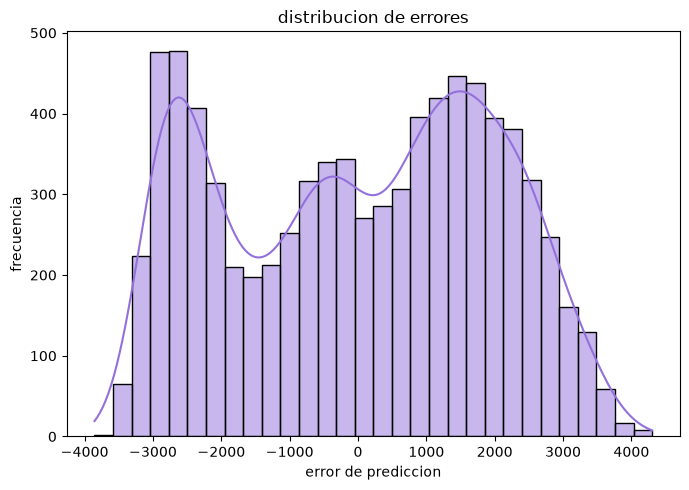

In [5]:
residuos = y_test - y_pred

plt.figure(figsize=(7, 5))
sns.histplot(residuos, bins=30, kde=True, color="mediumpurple")
plt.xlabel("error de prediccion")
plt.ylabel("frecuencia")
plt.title("distribucion de errores")
plt.tight_layout()
plt.show()

Peso de las variables

Los coeficientes muestran como cambia la prediccion con cada variable

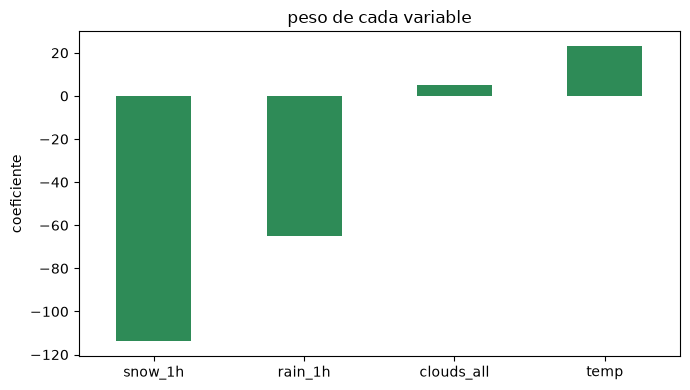

In [6]:
coeficientes = pd.Series(modelo.coef_, index=columnas)

plt.figure(figsize=(7, 4))
coeficientes.sort_values().plot(kind="bar", color="seagreen")
plt.ylabel("coeficiente")
plt.title("peso de cada variable")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Las features numericas del dataset no tienen relacion lineal con traffic_volume